# Predicting term-deposit subscriptions in a bank telemarketing campaign

Final project of the AI Specialisation at Tokio School. The dataset is **Bank Marketing**: the phone contacts made in the campaigns of a **Portuguese bank** between May 2008 and November 2010.

Each row is a **phone contact** with a client. The last column, `y`, says whether the client **subscribed** to a term deposit ("yes") or **not** ("no"). The goal is to train a model that **predicts who will subscribe**.

The notebook follows eight steps:

- **Step 1:** problem and dataset;
- **Step 2:** data description;
- **Step 3:** preprocessing;
- **Step 4:** feature engineering;
- **Step 5:** train, validation and test split;
- **Step 6:** modelling;
- **Step 7:** evaluation and interpretation;
- **Step 8:** conclusions.

**Before running:** the file `bank-additional-full.csv` must be **in the same folder** as this notebook.

# Step 1. Problem and dataset

#### The problem

A Portuguese bank runs phone campaigns to sell **term deposits**. Operators call thousands of clients, but only a small share accepts. Every call costs time and money, and calling people who are not interested annoys them.

The question of this project is: **using only what the bank knows before calling, can we predict whether the client will subscribe?**

The answer is "yes" or "no", so this is a **classification** problem in **supervised learning**: the model learns from past contacts whose outcome is already known.

#### Objectives

1. Describe and prepare the campaign data.
2. Train **two different models** that predict subscription.
3. Compare the models with suitable metrics and choose the best one.
4. Understand which variables weigh most in the prediction.

#### Why it matters

With a model like this, the bank can **call first the clients most likely to subscribe**. It makes fewer calls for the same number of sales, spends less and bothers fewer clients.

#### The dataset

- **Name:** Bank Marketing (version with social and economic context), file `bank-additional-full.csv`.
- **Source:** downloaded from Kaggle (https://www.kaggle.com/datasets/henriqueyamahata/bank-marketing). The original data is in the UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/222/bank+marketing).
- **Authors:** Sérgio Moro (ISCTE-IUL), Paulo Cortez (University of Minho) and Paulo Rita (ISCTE-IUL).
- **Citation requested by the authors:** S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, Elsevier, 62:22-31, June 2014.

The file `bank-additional-names.txt`, which comes with the data, describes each column. The table below summarises it.

| Column | Group | What it is |
|---|---|---|
| `age` | Client | Age |
| `job` | Client | Type of job |
| `marital` | Client | Marital status ("divorced" includes widowed) |
| `education` | Client | Education level |
| `default` | Client | Has credit in default? |
| `housing` | Client | Has a housing loan? |
| `loan` | Client | Has a personal loan? |
| `contact` | Last contact | Contact type (cellular or telephone) |
| `month` | Last contact | Month of the last contact |
| `day_of_week` | Last contact | Day of the week of the last contact |
| `duration` | Last contact | Duration of the last call, in seconds |
| `campaign` | Campaigns | Number of contacts made to this client in this campaign |
| `pdays` | Campaigns | Days since the last contact in a previous campaign (999 = never contacted) |
| `previous` | Campaigns | Number of contacts made to this client before this campaign |
| `poutcome` | Campaigns | Outcome of the previous campaign |
| `emp.var.rate` | Economic context | Employment variation rate (quarterly) |
| `cons.price.idx` | Economic context | Consumer price index (monthly) |
| `cons.conf.idx` | Economic context | Consumer confidence index (monthly) |
| `euribor3m` | Economic context | 3-month Euribor rate (daily) |
| `nr.employed` | Economic context | Number of employees (quarterly) |
| `y` | Target | Did the client subscribe to the term deposit? ("yes" or "no") |

#### Import the libraries

In [1]:
# The time module, to measure how long training takes
import time

# The random module, to sample the neural network parameter combinations
import random

# NumPy, with the usual alias np, for array calculations
import numpy as np

# pandas, with the usual alias pd, to work with the contacts table
import pandas as pd

# matplotlib's pyplot, with the usual alias plt, for the charts
import matplotlib.pyplot as plt

# scikit-learn function that splits the data into sets (train, validation and test)
from sklearn.model_selection import train_test_split

# scikit-learn standardisation of the numeric columns (mean 0 and standard deviation 1)
from sklearn.preprocessing import StandardScaler

# scikit-learn principal component analysis (PCA), for dimensionality reduction
from sklearn.decomposition import PCA

# scikit-learn random forest (Model 1)
from sklearn.ensemble import RandomForestClassifier

# scikit-learn grid search and cross-validation with stratified folds
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# scikit-learn evaluation metrics, confusion matrix and ROC curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve

# Keras, TensorFlow's high-level interface for neural networks (Model 2)
from tensorflow import keras

# Keras sequential model and network layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

# Keras Adam optimiser, AUC metric and early stopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import AUC
from tensorflow.keras.callbacks import EarlyStopping

# Wider table printing, so columns are not cut into several lines
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

print("Libraries imported successfully.")

Libraries imported successfully.


# Step 2. Data description

#### 2.1 Load the data and check the number of samples and variables

The CSV file is loaded with pandas. In this file the columns are separated by **semicolons**, so `sep=";"` is used. The result is a **DataFrame** (a table) called `contacts`.

In [2]:
# Load the CSV file into a DataFrame (columns are separated by semicolons)
contacts = pd.read_csv("bank-additional-full.csv", sep=";")

# Number of rows (samples) and columns (variables)
number_of_contacts, number_of_columns = contacts.shape
print(f"Number of contacts (samples): {number_of_contacts}")
print(f"Number of columns: {number_of_columns}")
print(f"Input variables: {number_of_columns - 1}, plus the y column (target)")

# First 5 contacts
print("\nFirst 5 contacts:")
print(contacts.head())

Number of contacts (samples): 41188
Number of columns: 21
Input variables: 20, plus the y column (target)

First 5 contacts:
   age        job  marital    education  default housing loan    contact month day_of_week  duration  campaign  pdays  previous     poutcome  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   may         mon       261         1    999         0  nonexistent           1.1          93.994          -36.4      4.857   
1   57   services  married  high.school  unknown      no   no  telephone   may         mon       149         1    999         0  nonexistent           1.1          93.994          -36.4      4.857   
2   37   services  married  high.school       no     yes   no  telephone   may         mon       226         1    999         0  nonexistent           1.1          93.994          -36.4      4.857   
3   40     admin.  married     basic.6y       no      no   no  telephone   

#### 2.2 Data types

The `info()` method shows the type of each column and how many non-null values it has. The column names are then split into two lists: **numeric** and **categorical** (text). `select_dtypes` picks columns by type: `include="number"` keeps the numeric ones and `exclude="number"` keeps the rest.

In [3]:
# Type of each column and number of non-null values
print("Column information:\n")
contacts.info()

Column information:

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188

In [4]:
# Names of the numeric columns (integers and decimals)
numeric_columns = list(contacts.select_dtypes(include="number").columns)

# Names of the categorical (text) columns, including the target y
categorical_columns = list(contacts.select_dtypes(exclude="number").columns)

print(f"Numeric columns ({len(numeric_columns)}): {numeric_columns}")
print(f"\nCategorical columns ({len(categorical_columns)}): {categorical_columns}")

Numeric columns (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical columns (11): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


In [5]:
# Descriptive statistics of the numeric columns (mean, standard deviation, minimum, quartiles and maximum)
print("Descriptive statistics of the numeric columns:\n")
print(contacts[numeric_columns].describe().round(2))

Descriptive statistics of the numeric columns:

            age  duration  campaign     pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
count  41188.00  41188.00  41188.00  41188.00  41188.00      41188.00        41188.00       41188.00   41188.00     41188.00
mean      40.02    258.29      2.57    962.48      0.17          0.08           93.58         -40.50       3.62      5167.04
std       10.42    259.28      2.77    186.91      0.49          1.57            0.58           4.63       1.73        72.25
min       17.00      0.00      1.00      0.00      0.00         -3.40           92.20         -50.80       0.63      4963.60
25%       32.00    102.00      1.00    999.00      0.00         -1.80           93.08         -42.70       1.34      5099.10
50%       38.00    180.00      2.00    999.00      0.00          1.10           93.75         -41.80       4.86      5191.00
75%       47.00    319.00      3.00    999.00      0.00          1.40        

In [6]:
# For each categorical column, how many different categories it has and which ones
print("Categories in each categorical column:\n")
for column_name in categorical_columns:
    categories = contacts[column_name].unique()
    print(f"{column_name} ({len(categories)} categories): {list(categories)}")

Categories in each categorical column:

job (12 categories): ['housemaid', 'services', 'admin.', 'blue-collar', 'technician', 'retired', 'management', 'unemployed', 'self-employed', 'unknown', 'entrepreneur', 'student']
marital (4 categories): ['married', 'single', 'divorced', 'unknown']
education (8 categories): ['basic.4y', 'high.school', 'basic.6y', 'basic.9y', 'professional.course', 'unknown', 'university.degree', 'illiterate']
default (3 categories): ['no', 'unknown', 'yes']
housing (3 categories): ['no', 'yes', 'unknown']
loan (3 categories): ['no', 'yes', 'unknown']
contact (2 categories): ['telephone', 'cellular']
month (10 categories): ['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'mar', 'apr', 'sep']
day_of_week (5 categories): ['mon', 'tue', 'wed', 'thu', 'fri']
poutcome (3 categories): ['nonexistent', 'failure', 'success']
y (2 categories): ['no', 'yes']


#### 2.3 Missing values

First we check for null values (`NaN`). Then we count the **"unknown"** category. According to the data documentation, this is how the authors marked missing values in the categorical columns. pandas does not count them as nulls, because "unknown" is just another piece of text.

In [7]:
# Count the null values (NaN) in the whole table
number_of_null_values = contacts.isnull().sum().sum()
print(f"Null values (NaN) in the whole table: {number_of_null_values}")

Null values (NaN) in the whole table: 0


In [8]:
# In each categorical column, count the contacts with the "unknown" category (missing value)
unknown_table_rows = []
for column_name in categorical_columns:
    unknown_count = (contacts[column_name] == "unknown").sum()
    # Keep only the columns with at least one "unknown"
    if unknown_count > 0:
        unknown_percentage = unknown_count / number_of_contacts * 100
        unknown_table_rows.append({
            "column": column_name,
            "unknown_count": unknown_count,
            "percentage": round(unknown_percentage, 2),
        })

# Put the results in a table, from the column with most missing values to the one with fewest
unknown_table = pd.DataFrame(unknown_table_rows)
unknown_table = unknown_table.sort_values(by="unknown_count", ascending=False)
unknown_table = unknown_table.reset_index(drop=True)

print('Missing values ("unknown" category) per column:\n')
print(unknown_table)

# Count the contacts with "unknown" in at least one column
has_any_unknown = (contacts[categorical_columns] == "unknown").any(axis=1)
contacts_with_unknown = has_any_unknown.sum()
contacts_with_unknown_percentage = contacts_with_unknown / number_of_contacts * 100
print(f'\nContacts with "unknown" in at least one column: {contacts_with_unknown} ({contacts_with_unknown_percentage:.1f}%)')

Missing values ("unknown" category) per column:

      column  unknown_count  percentage
0    default           8597       20.87
1  education           1731        4.20
2    housing            990        2.40
3       loan            990        2.40
4        job            330        0.80
5    marital             80        0.19

Contacts with "unknown" in at least one column: 10700 (26.0%)


There is also a special value in a numeric column. In `pdays`, the number **999** does not mean 999 days: it means the client was **never contacted** in a previous campaign. It is another kind of missing value, so it is counted separately.

In [9]:
# Count the contacts where pdays is 999 (client never contacted in a previous campaign)
pdays_999_count = (contacts["pdays"] == 999).sum()
pdays_999_percentage = pdays_999_count / number_of_contacts * 100
print(f"Contacts with pdays equal to 999: {pdays_999_count} ({pdays_999_percentage:.1f}%)")
print(f"Contacts with a real pdays value: {number_of_contacts - pdays_999_count}")

Contacts with pdays equal to 999: 39673 (96.3%)
Contacts with a real pdays value: 1515


We also check for **duplicate rows**. The `duplicated()` method marks with `True` the rows that are identical to an earlier one.

In [10]:
# Count the rows that are an exact copy of another row
duplicate_rows = contacts.duplicated().sum()
print(f"Duplicate rows: {duplicate_rows}")

Duplicate rows: 12


#### 2.4 Outliers

An **outlier** is a value far away from the rest. To find them we use the **interquartile range rule**:

- the 1st quartile (Q1) is the value below which 25% of the data lies, and the 3rd quartile (Q3) the value below which 75% lies;
- the interquartile range is Q3 − Q1;
- a value is an outlier if it is below Q1 − 1.5 × range or above Q3 + 1.5 × range.

pandas' `quantile` method computes the quartiles. It is the same rule **boxplots** use to draw the separate points.

In [11]:
# Apply the interquartile range rule to each numeric column
outlier_table_rows = []
for column_name in numeric_columns:
    # Quartiles and interquartile range of the column
    first_quartile = contacts[column_name].quantile(0.25)
    third_quartile = contacts[column_name].quantile(0.75)
    interquartile_range = third_quartile - first_quartile

    # Limits beyond which a value is an outlier
    lower_limit = first_quartile - 1.5 * interquartile_range
    upper_limit = third_quartile + 1.5 * interquartile_range

    # Count the values outside the limits
    is_outlier = (contacts[column_name] < lower_limit) | (contacts[column_name] > upper_limit)
    outlier_count = is_outlier.sum()

    outlier_table_rows.append({
        "column": column_name,
        "lower_limit": round(lower_limit, 2),
        "upper_limit": round(upper_limit, 2),
        "minimum": contacts[column_name].min(),
        "maximum": contacts[column_name].max(),
        "outlier_count": outlier_count,
        "percentage": round(outlier_count / number_of_contacts * 100, 2),
    })

# Put the results in a table
outlier_table = pd.DataFrame(outlier_table_rows)
print("Outliers per numeric column (interquartile range rule):\n")
print(outlier_table)

Outliers per numeric column (interquartile range rule):

           column  lower_limit  upper_limit   minimum   maximum  outlier_count  percentage
0             age         9.50        69.50    17.000    98.000            469        1.14
1        duration      -223.50       644.50     0.000  4918.000           2963        7.19
2        campaign        -2.00         6.00     1.000    56.000           2406        5.84
3           pdays       999.00       999.00     0.000   999.000           1515        3.68
4        previous         0.00         0.00     0.000     7.000           5625       13.66
5    emp.var.rate        -6.60         6.20    -3.400     1.400              0        0.00
6  cons.price.idx        91.70        95.37    92.201    94.767              0        0.00
7   cons.conf.idx       -52.15       -26.95   -50.800   -26.900            447        1.09
8       euribor3m        -4.08        10.39     0.634     5.045              0        0.00
9     nr.employed      4905.60   

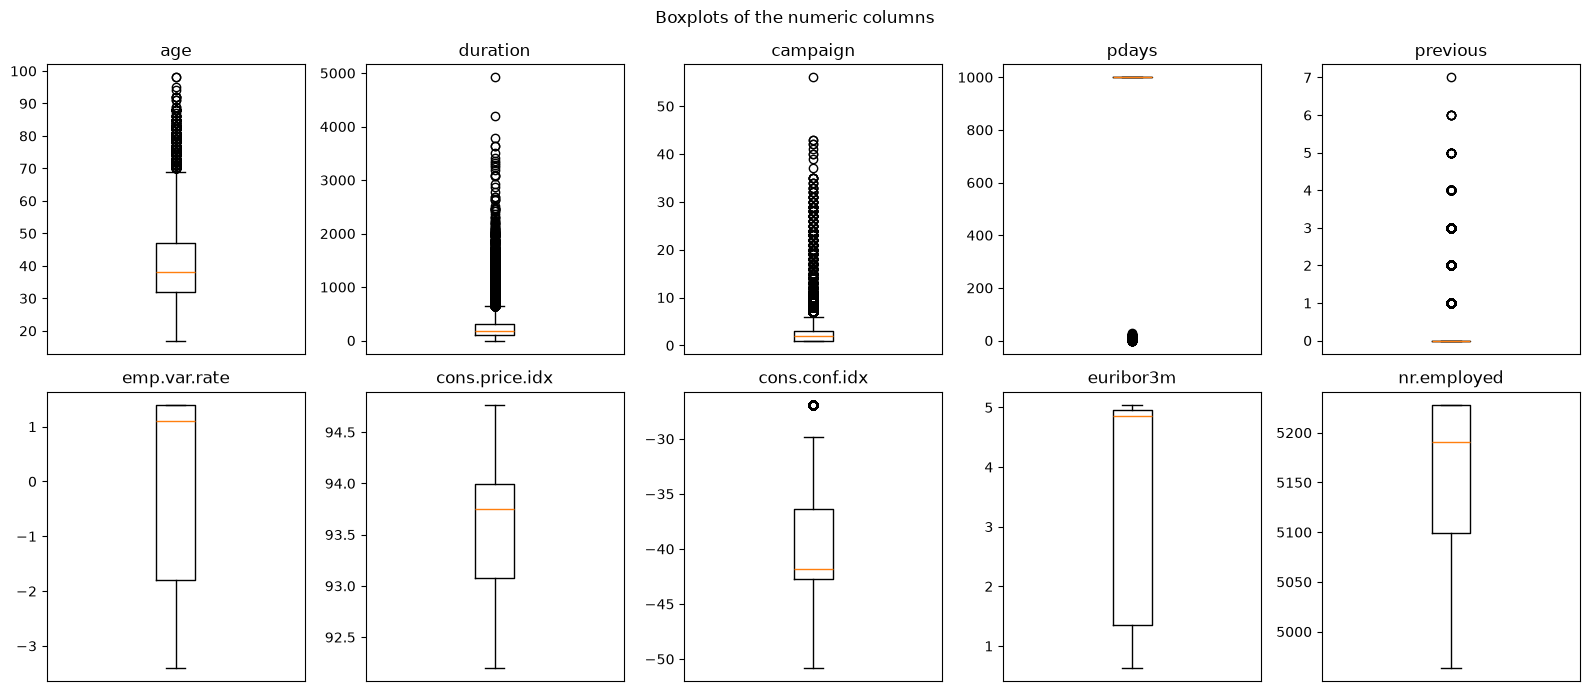

In [12]:
# Boxplots of the numeric columns: the separate points are the outliers
figure, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.ravel()

for position, column_name in enumerate(numeric_columns):
    axes[position].boxplot(contacts[column_name])
    axes[position].set_title(column_name)
    axes[position].set_xticks([])

figure.suptitle("Boxplots of the numeric columns")
plt.tight_layout()
plt.show()

**Reading the results:**

- `age`: the outliers are clients over 69. They are real ages, not errors.
- `duration` and `campaign`: long tail to the right. Most calls are short and most clients get few contacts, but there are very long calls and clients contacted dozens of times.
- `pdays` and `previous`: the rule flags everything that differs from the most common value (999 in `pdays` and 0 in `previous`). These are not wrong values: they are the clients who had been contacted before.
- `cons.conf.idx`: the outliers are all contacts made in October, when the index had its highest value in the table (−26.9).
- The other economic context columns have no outliers.

In other words, the rule flags **rare but plausible values**. What to do with them is decided in preprocessing (Step 3).

#### 2.5 Class imbalance

The `y` column is the **target**. We count how many contacts ended in a subscription and how many did not. We also create the `subscribed` column, with 1 for those who subscribed and 0 for those who did not, because models need numbers.

In [13]:
# Count how many contacts ended in a subscription (yes) and how many did not (no)
target_counts = contacts["y"].value_counts()
print("Number of contacts per value of y:")
print(target_counts)

# Percentage of each class
subscribed_percentage = target_counts["yes"] / number_of_contacts * 100
not_subscribed_percentage = target_counts["no"] / number_of_contacts * 100
print(f"\nSubscribed: {subscribed_percentage:.2f}%")
print(f"Did not subscribe: {not_subscribed_percentage:.2f}%")
print(f"For each subscription there are {target_counts['no'] / target_counts['yes']:.1f} contacts without one.")

# Numeric column subscribed: 1 if y is "yes", 0 if "no"
contacts["subscribed"] = (contacts["y"] == "yes").astype(int)

Number of contacts per value of y:
y
no     36548
yes     4640
Name: count, dtype: int64

Subscribed: 11.27%
Did not subscribe: 88.73%
For each subscription there are 7.9 contacts without one.


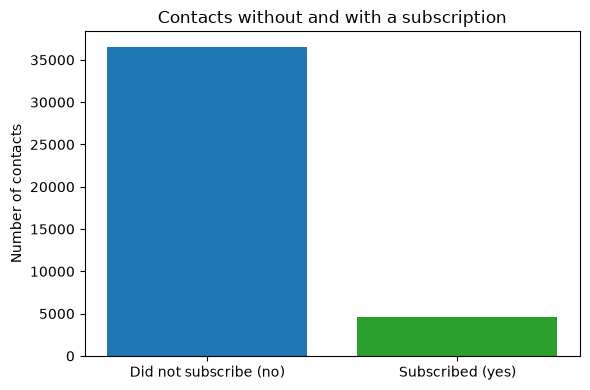

In [14]:
# Chart: number of contacts without and with a subscription
plt.figure(figsize=(6, 4))
plt.bar(["Did not subscribe (no)", "Subscribed (yes)"], [target_counts["no"], target_counts["yes"]], color=["tab:blue", "tab:green"])
plt.title("Contacts without and with a subscription")
plt.ylabel("Number of contacts")
plt.tight_layout()
plt.show()

The classes are **imbalanced**: the vast majority of contacts do not end in a subscription. This has two consequences for the next steps:

- **accuracy is misleading**. A model that always answered "no" would be right almost 89% of the time without finding a single interested client. So the evaluation also looks at precision, recall, F1-score and the ROC curve;
- the data split (Step 5) must **keep the same share** of subscriptions in train, validation and test.

#### 2.6 The `duration` column

The data documentation warns about the `duration` column (length of the last call): it is strongly linked to the outcome, but **it is only known after the call ends**, and by then the outcome is known too. The next cells confirm that link.

In [15]:
# Mean and median call duration, with and without a subscription
mean_duration_by_outcome = contacts.groupby("y")["duration"].mean()
median_duration_by_outcome = contacts.groupby("y")["duration"].median()

print("Mean call duration, in seconds:")
print(mean_duration_by_outcome.round(1))
print("\nMedian call duration, in seconds:")
print(median_duration_by_outcome)

# Calls with duration 0: no conversation, so there cannot have been a subscription
zero_duration_calls = contacts[contacts["duration"] == 0]
print(f"\nCalls with duration 0: {len(zero_duration_calls)}")
print(f"Subscriptions in those calls: {zero_duration_calls['subscribed'].sum()}")

Mean call duration, in seconds:
y
no     220.8
yes    553.2
Name: duration, dtype: float64

Median call duration, in seconds:
y
no     163.5
yes    449.0
Name: duration, dtype: float64

Calls with duration 0: 4
Subscriptions in those calls: 0


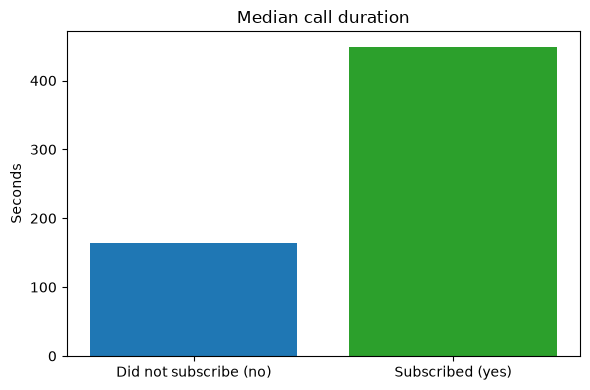

In [16]:
# Chart: median call duration, without and with a subscription
plt.figure(figsize=(6, 4))
plt.bar(["Did not subscribe (no)", "Subscribed (yes)"], [median_duration_by_outcome["no"], median_duration_by_outcome["yes"]], color=["tab:blue", "tab:green"])
plt.title("Median call duration")
plt.ylabel("Seconds")
plt.tight_layout()
plt.show()

Calls that end in a subscription are much longer. That makes sense: an interested client stays on the line to hear the terms. But the goal is to predict **before calling**, and before calling the duration does not exist. Using it would give the model information the bank does not have at that moment (data leakage).

So `duration` **is left out of the models**. It is described here because it is part of the data, and it is removed in preprocessing (Step 3).

#### 2.7 Summary of the data description

In [17]:
# Summary with the numbers computed in the previous cells
print("Summary of the data description")
print("-------------------------------")
print(f"Samples (contacts): {number_of_contacts}")
print(f"Input variables: {number_of_columns - 1}, plus the target y")
print(f"Numeric columns: {len(numeric_columns)}")
print(f"Categorical columns (including the target): {len(categorical_columns)}")
print(f"Null values (NaN): {number_of_null_values}")
print(f'Columns with the "unknown" category: {len(unknown_table)}')
print(f'Contacts with "unknown" in at least one column: {contacts_with_unknown} ({contacts_with_unknown_percentage:.1f}%)')
print(f"Contacts with pdays equal to 999: {pdays_999_count} ({pdays_999_percentage:.1f}%)")
print(f"Duplicate rows: {duplicate_rows}")
print(f"Numeric columns with outliers: {(outlier_table['outlier_count'] > 0).sum()} of {len(numeric_columns)}")
print(f"Subscriptions (class yes): {target_counts['yes']} ({subscribed_percentage:.2f}%)")
print(f"No subscription (class no): {target_counts['no']} ({not_subscribed_percentage:.2f}%)")

Summary of the data description
-------------------------------
Samples (contacts): 41188
Input variables: 20, plus the target y
Numeric columns: 10
Categorical columns (including the target): 11
Null values (NaN): 0
Columns with the "unknown" category: 6
Contacts with "unknown" in at least one column: 10700 (26.0%)
Contacts with pdays equal to 999: 39673 (96.3%)
Duplicate rows: 12
Numeric columns with outliers: 6 of 10
Subscriptions (class yes): 4640 (11.27%)
No subscription (class no): 36548 (88.73%)


**What preprocessing (Step 3) has to deal with:**

- the missing values marked as "unknown";
- the special value 999 in `pdays`;
- the duplicate rows;
- the rare values (outliers) in the numeric columns;
- the `duration` column, which leaves the models;
- the categorical columns, which must become numbers;
- the numeric columns, which are on very different scales.

# Step 3. Preprocessing

This step fixes the problems found in the data description, in this order:

1. remove the duplicate rows;
2. remove the `duration` column;
3. handle the missing values ("unknown");
4. handle the special value 999 in `pdays`;
5. convert the categorical columns into numbers;
6. put the numeric columns on the same scale (standardisation).

Point 6 is explained here but only computed in Step 5, after the data split. Section 3.6 explains why.

#### 3.1 Duplicate rows

`drop_duplicates()` removes rows that are an exact copy of another and keeps the first of each group. This is done **before** removing `duration`: without the duration, many different calls would look identical and be removed by mistake.

In [18]:
# Remove rows that are an exact copy of another (keeps the first of each group)
contacts = contacts.drop_duplicates()

# Reset the index so it runs 0, 1, 2, ...
contacts = contacts.reset_index(drop=True)

contacts_after_cleaning = len(contacts)
print(f"Contacts before: {number_of_contacts}")
print(f"Duplicate rows removed: {number_of_contacts - contacts_after_cleaning}")
print(f"Contacts after: {contacts_after_cleaning}")

Contacts before: 41188
Duplicate rows removed: 12
Contacts after: 41176


#### 3.2 Remove the `duration` column

As explained in section 2.6, the call duration is only known after the call ends. It is removed so the model only works with what the bank knows before calling.

In [19]:
# Remove the duration column (axis=1 means a column is dropped)
contacts = contacts.drop(["duration"], axis=1)

print(f"Number of columns after removing duration: {len(contacts.columns)}")
print(list(contacts.columns))

Number of columns after removing duration: 21
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'subscribed']


#### 3.3 Missing values ("unknown")

There are three ways to handle a missing value: **drop** the row, **replace** the value, or **keep** "unknown" as one more category.

Dropping rows is not a good option, because 26% of the contacts have at least one "unknown". The columns are handled in two ways:

- in `job`, `marital`, `education`, `housing` and `loan`, where "unknown" is under 5%, it is **replaced by the most frequent category** of the column;
- in `default`, where it is about 21%, **"unknown" is kept as a category**.

The next cell shows why: clients with an unknown `default` subscribe much less than those with "no". The "we don't know" is information in itself. Replacing it with "no" would erase that difference and invent the answer for a fifth of the clients.

In [20]:
# Subscription rate (%) and number of contacts in each default category
subscription_rate_by_default = contacts.groupby("default")["subscribed"].mean() * 100
contacts_by_default = contacts.groupby("default").size()

print("Subscription rate by default category (%):")
print(subscription_rate_by_default.round(1))
print("\nNumber of contacts by default category:")
print(contacts_by_default)

Subscription rate by default category (%):
default
no         12.9
unknown     5.2
yes         0.0
Name: subscribed, dtype: float64

Number of contacts by default category:
default
no         32577
unknown     8596
yes            3
dtype: int64


In [21]:
# Columns where "unknown" is replaced by the most frequent category
columns_to_impute = ["job", "marital", "education", "housing", "loan"]

# Keep a copy of these columns as they are now, for the check in Step 5
columns_before_imputation = contacts[columns_to_impute].copy()

# Dictionary with the category used in each column
most_frequent_categories = {}

for column_name in columns_to_impute:
    # value_counts counts the contacts in each category; idxmax returns the category with the highest count
    most_frequent_category = contacts[column_name].value_counts().idxmax()
    most_frequent_categories[column_name] = most_frequent_category

    # Replace "unknown" with the most frequent category
    is_unknown = contacts[column_name] == "unknown"
    replaced_count = is_unknown.sum()
    contacts.loc[is_unknown, column_name] = most_frequent_category

    print(f'{column_name}: {replaced_count} "unknown" replaced with "{most_frequent_category}"')

job: 330 "unknown" replaced with "admin."
marital: 80 "unknown" replaced with "married"
education: 1730 "unknown" replaced with "university.degree"
housing: 990 "unknown" replaced with "yes"
loan: 990 "unknown" replaced with "no"


In [22]:
# Check: count the "unknown" values left in each categorical column
print('"unknown" left in each column:')
for column_name in ["job", "marital", "education", "default", "housing", "loan"]:
    unknown_left = (contacts[column_name] == "unknown").sum()
    print(f"{column_name}: {unknown_left}")

"unknown" left in each column:
job: 0
marital: 0
education: 0
default: 8596
housing: 0
loan: 0


#### 3.4 The special value 999 in `pdays`

999 means "never contacted in a previous campaign". A model would read 999 as a very large number of days, which is not true. So we create the column **`contacted_before`**, with 1 if the client had been contacted before and 0 if not, and remove `pdays`.

The exact number of days is lost, but it only existed for a small share of the contacts. What matters is kept: whether there was a previous contact.

In [23]:
# contacted_before: 1 if pdays has a real value, 0 if it is 999 (never contacted)
contacts["contacted_before"] = (contacts["pdays"] != 999).astype(int)

# Subscription rate (%) and number of contacts, for never contacted (0) and contacted before (1)
subscription_rate_by_previous_contact = contacts.groupby("contacted_before")["subscribed"].mean() * 100
contacts_by_previous_contact = contacts.groupby("contacted_before").size()

print("Subscription rate by contacted_before (%):")
print(subscription_rate_by_previous_contact.round(1))
print("\nNumber of contacts by contacted_before:")
print(contacts_by_previous_contact)

# Remove pdays, which is no longer needed
contacts = contacts.drop(["pdays"], axis=1)

Subscription rate by contacted_before (%):
contacted_before
0     9.3
1    63.8
Name: subscribed, dtype: float64

Number of contacts by contacted_before:
contacted_before
0    39661
1     1515
dtype: int64


#### 3.5 Encoding the categorical variables

Models only work with **numbers**. `pd.get_dummies` creates **one 0/1 column per category**. For example, `marital` becomes three columns: `marital_divorced`, `marital_married` and `marital_single`. In each row, only the column of the client's category has a 1.

`y` and `subscribed` are left out of the features, because they are the answer we want to predict. The answer is kept separately in the variable `target`.

In [24]:
# Features the models will use: every column except the answer (y and subscribed)
features = contacts.drop(["y", "subscribed"], axis=1)
columns_before_encoding = features.shape[1]

# Convert the text columns into 0/1 columns (one per category)
features = pd.get_dummies(features, dtype=int)

# The target is the subscribed column (1 = subscribed, 0 = did not subscribe)
target = contacts["subscribed"]

print(f"Columns before encoding: {columns_before_encoding}")
print(f"Columns after encoding: {features.shape[1]}")
print("\nColumn names:")
print(list(features.columns))

Columns before encoding: 19
Columns after encoding: 57

Column names:
['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'contacted_before', 'job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'marital_divorced', 'marital_married', 'marital_single', 'education_basic.4y', 'education_basic.6y', 'education_basic.9y', 'education_high.school', 'education_illiterate', 'education_professional.course', 'education_university.degree', 'default_no', 'default_unknown', 'default_yes', 'housing_no', 'housing_yes', 'loan_no', 'loan_yes', 'contact_cellular', 'contact_telephone', 'month_apr', 'month_aug', 'month_dec', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'day_of_week_fri', 'day_of_week_mon', 'day_of_week_thu', 'day_of_week_tue', 'day_of_week_wed', 'poutc

In [25]:
# Example: the marital column of the first 5 contacts, before and after encoding
print("Original marital column:")
print(contacts["marital"].head())
print("\nAfter encoding:")
print(features[["marital_divorced", "marital_married", "marital_single"]].head())

Original marital column:
0    married
1    married
2    married
3    married
4    married
Name: marital, dtype: str

After encoding:
   marital_divorced  marital_married  marital_single
0                 0                1               0
1                 0                1               0
2                 0                1               0
3                 0                1               0
4                 0                1               0


#### 3.6 Standardising the numeric columns

The numeric columns are on very different scales: age is in the tens and the number of employees in the thousands. The neural network learns poorly like this, because it gives more weight to columns with large numbers. The random forest does not have this problem.

**Standardisation** fixes it: subtract the column mean from each value and divide by the standard deviation. Every column ends up with **mean 0 and standard deviation 1**. In scikit-learn this is done with `StandardScaler`.

**Why it is only computed in Step 5.** The mean and standard deviation are "learned" from the data. If they were computed with all the contacts, the test data would enter the calculation and influence training. The test set must be data the model has **never seen**, not even indirectly. So:

1. first the data is split (Step 5);
2. the mean and standard deviation are computed **on the training set only**;
3. those same values are applied to validation and test.

It is the same care taken with `duration`: do not give the model information it would not have in reality.

# Step 4. Feature engineering

This step creates new variables from the existing ones and looks at dimensionality reduction.

#### 4.1 New variables

The first new variable was already created in section 3.4: **`contacted_before`**, from `pdays`.

The second is **`age_group`**, from `age`. Age is a number, but its relationship with subscription is not a straight line, as the next cell shows. Grouping ages makes that pattern visible. The `age` column is kept.

In [26]:
# Age groups: name, minimum age and maximum age of each one
age_group_limits = [
    ("up_to_24", 0, 24),
    ("25_to_34", 25, 34),
    ("35_to_44", 35, 44),
    ("45_to_54", 45, 54),
    ("55_to_64", 55, 64),
    ("65_plus", 65, 200),
]

# Create the age_group column and fill it, group by group, with a condition on age
contacts["age_group"] = ""
age_group_names = []
for group_name, minimum_age, maximum_age in age_group_limits:
    in_group = (contacts["age"] >= minimum_age) & (contacts["age"] <= maximum_age)
    contacts.loc[in_group, "age_group"] = group_name
    age_group_names.append(group_name)

# Subscription rate (%) and number of contacts per age group, in age order
subscription_rate_by_age_group = contacts.groupby("age_group")["subscribed"].mean() * 100
subscription_rate_by_age_group = subscription_rate_by_age_group.loc[age_group_names]
contacts_by_age_group = contacts.groupby("age_group").size().loc[age_group_names]

print("Subscription rate by age group (%):")
print(subscription_rate_by_age_group.round(1))
print("\nNumber of contacts by age group:")
print(contacts_by_age_group)

Subscription rate by age group (%):
age_group
up_to_24    24.0
25_to_34    12.2
35_to_44     8.7
45_to_54     8.6
55_to_64    13.6
65_plus     47.3
Name: subscribed, dtype: float64

Number of contacts by age group:
age_group
up_to_24     1067
25_to_34    13684
35_to_44    13495
45_to_54     8702
55_to_64     3566
65_plus       662
dtype: int64


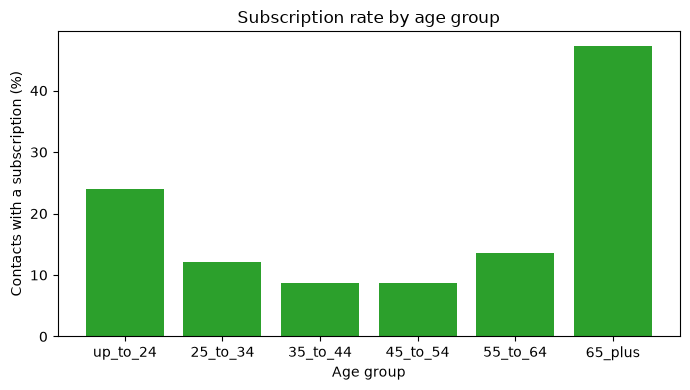

In [27]:
# Chart: subscription rate (%) by age group
plt.figure(figsize=(7, 4))
plt.bar(subscription_rate_by_age_group.index, subscription_rate_by_age_group.values, color="tab:green")
plt.title("Subscription rate by age group")
plt.xlabel("Age group")
plt.ylabel("Contacts with a subscription (%)")
plt.tight_layout()
plt.show()

The chart has a **U shape**: the youngest and, above all, the oldest clients subscribe much more than those in the middle age groups. They are also the groups with fewest contacts.

The new column is categorical, so it is added to the features and encoded with `pd.get_dummies`, like the others.

In [28]:
# Add the age group to the features and convert it into 0/1 columns
features["age_group"] = contacts["age_group"]
features = pd.get_dummies(features, columns=["age_group"], dtype=int)

print(f"Number of features after adding the age group: {features.shape[1]}")
print("\nAge group columns:")
print([column_name for column_name in features.columns if column_name.startswith("age_group")])

Number of features after adding the age group: 63

Age group columns:
['age_group_25_to_34', 'age_group_35_to_44', 'age_group_45_to_54', 'age_group_55_to_64', 'age_group_65_plus', 'age_group_up_to_24']


#### 4.2 Dimensionality reduction

Reducing dimensionality means **reducing the number of variables** by combining those that say the same thing. To see whether it makes sense here, we compute the **correlation** between the five economic indicators. Correlation goes from −1 to 1: close to 1 means two columns rise and fall together. pandas' `corr()` computes it for every pair of columns.

In [29]:
# The five economic context indicators
indicator_columns = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

# Correlation between the indicators (from -1 to 1)
indicator_correlation = contacts[indicator_columns].corr()
print("Correlation between the economic indicators:\n")
print(indicator_correlation.round(2))

Correlation between the economic indicators:

                emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
emp.var.rate            1.00            0.78           0.20       0.97         0.91
cons.price.idx          0.78            1.00           0.06       0.69         0.52
cons.conf.idx           0.20            0.06           1.00       0.28         0.10
euribor3m               0.97            0.69           0.28       1.00         0.95
nr.employed             0.91            0.52           0.10       0.95         1.00


Three indicators (`emp.var.rate`, `euribor3m` and `nr.employed`) have correlations above 0.9 with each other. They say almost the same thing: how the economy was doing at the time of the contact. Keeping all three repeats information.

**Principal component analysis** (PCA) solves this. It creates new columns, called **components**, that are combinations of the original columns. The components are ordered: the first keeps most of the information (variance), the second most of what is left, and so on. Only the first ones are kept and the rest are dropped, losing little information.

PCA is applied **only to the five economic indicators**, which is where the repetition is. Applying it to all the columns would make it impossible to say which variables weigh in the prediction, which is one of the project's goals.

Like standardisation, PCA "learns" from the data. So it is also only computed in Step 5, **on the training set only**.

# Step 5. Data split

#### 5.1 Train, validation and test

The contacts are split into three sets:

- **train (70%)**: the data the models learn from;
- **validation (15%)**: used to tune the models and choose the best settings;
- **test (15%)**: kept aside until the end, for the final evaluation with data the models have never seen.

`train_test_split` splits in two, so it is used twice: first train (70%) is separated from the rest (30%), then the rest is split in half. In both:

- `random_state=90` fixes the random seed, so the result is always the same;
- `stratify` keeps **the same share of subscriptions** in all three sets, which matters with imbalanced classes.

`X` are the features and `y` is the correct answer (subscribed or not).

In [30]:
# First split: 70% for training and 30% for the rest
X_train, X_rest, y_train, y_rest = train_test_split(
    features, target, test_size=0.30, random_state=90, stratify=target
)

# Second split: the rest is split in half, 15% for validation and 15% for test
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=90, stratify=y_rest
)

total_contacts = len(features)
print(f"Train: {len(X_train)} contacts ({len(X_train) / total_contacts * 100:.1f}%), subscriptions: {y_train.mean() * 100:.2f}%")
print(f"Validation: {len(X_val)} contacts ({len(X_val) / total_contacts * 100:.1f}%), subscriptions: {y_val.mean() * 100:.2f}%")
print(f"Test: {len(X_test)} contacts ({len(X_test) / total_contacts * 100:.1f}%), subscriptions: {y_test.mean() * 100:.2f}%")

Train: 28823 contacts (70.0%), subscriptions: 11.27%
Validation: 6176 contacts (15.0%), subscriptions: 11.27%
Test: 6177 contacts (15.0%), subscriptions: 11.27%


#### 5.2 Checking the missing-value imputation

In section 3.3, the most frequent category of each column was computed with all the contacts. To confirm that this brought no information from validation or test, the count is repeated **with the training contacts only** and compared.

In [31]:
# For each column, compute the most frequent category using only the training contacts (ignoring "unknown")
print("Most frequent category computed on the training set only:")
for column_name in columns_to_impute:
    train_column = columns_before_imputation.loc[X_train.index, column_name]
    train_column_known = train_column[train_column != "unknown"]
    most_frequent_in_train = train_column_known.value_counts().idxmax()

    is_same = most_frequent_in_train == most_frequent_categories[column_name]
    print(f"{column_name}: {most_frequent_in_train} (same as used in section 3.3: {is_same})")

Most frequent category computed on the training set only:
job: admin. (same as used in section 3.3: True)
marital: married (same as used in section 3.3: True)
education: university.degree (same as used in section 3.3: True)
housing: yes (same as used in section 3.3: True)
loan: no (same as used in section 3.3: True)


#### 5.3 PCA of the economic indicators, fitted on the training set only

PCA needs columns on the same scale. Otherwise the indicator with the largest numbers (`nr.employed`, in the thousands) would dominate the components. So the steps are:

1. **standardise** the five indicators with the training mean and standard deviation;
2. **fit PCA** on the training set and see how much information each component keeps;
3. keep the **smallest number of components that keeps at least 95%** of the information;
4. apply the same transformation to validation and test.

In scikit-learn, `fit` learns from the data (here, the training set only) and `transform` applies what was learned.

In [32]:
# Indicator scaler: learns the mean and standard deviation from the training set only
indicator_scaler = StandardScaler()
indicator_scaler.fit(X_train[indicator_columns])

# Apply the standardisation to the three sets, with the values learned from training
indicators_train = indicator_scaler.transform(X_train[indicator_columns])
indicators_val = indicator_scaler.transform(X_val[indicator_columns])
indicators_test = indicator_scaler.transform(X_test[indicator_columns])

# PCA with all components, just to see how much information (variance) each one keeps
pca_full = PCA()
pca_full.fit(indicators_train)

variance_per_component = pca_full.explained_variance_ratio_ * 100
cumulative_variance = np.cumsum(variance_per_component)

print("Information (variance) kept by each component:")
for position in range(len(variance_per_component)):
    print(f"Component {position + 1}: {variance_per_component[position]:.1f}% (cumulative: {cumulative_variance[position]:.1f}%)")

# Smallest number of components that keeps at least 95% of the information:
# count the components where the cumulative value is still below 95% and add 1
n_components = int((cumulative_variance < 95).sum()) + 1
print(f"\nComponents needed to keep at least 95%: {n_components}")

Information (variance) kept by each component:
Component 1: 69.5% (cumulative: 69.5%)
Component 2: 19.7% (cumulative: 89.2%)
Component 3: 10.1% (cumulative: 99.3%)
Component 4: 0.5% (cumulative: 99.8%)
Component 5: 0.2% (cumulative: 100.0%)

Components needed to keep at least 95%: 3


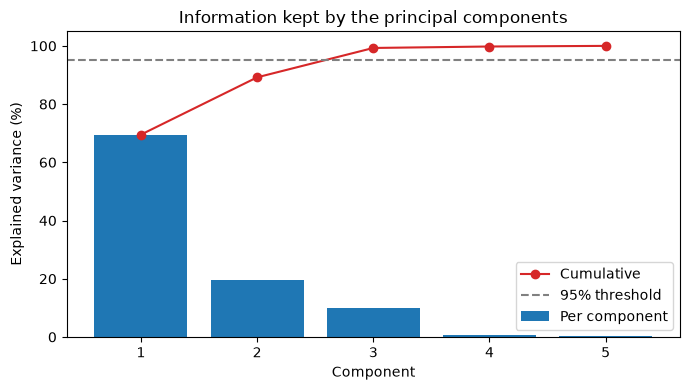

In [33]:
# Chart: information kept by each component (bars) and cumulative (line)
component_numbers = list(range(1, len(variance_per_component) + 1))

plt.figure(figsize=(7, 4))
plt.bar(component_numbers, variance_per_component, color="tab:blue", label="Per component")
plt.plot(component_numbers, cumulative_variance, color="tab:red", marker="o", label="Cumulative")
plt.axhline(95, color="gray", linestyle="--", label="95% threshold")
plt.title("Information kept by the principal components")
plt.xlabel("Component")
plt.ylabel("Explained variance (%)")
plt.xticks(component_numbers)
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
# Final PCA, with only the chosen number of components, fitted on the training set
pca = PCA(n_components=n_components)
pca.fit(indicators_train)

# Transform the indicators of the three sets into components
components_train = pca.transform(indicators_train)
components_val = pca.transform(indicators_val)
components_test = pca.transform(indicators_test)

# Names of the new columns: economic_component_1, economic_component_2, ...
component_names = []
for number in range(1, n_components + 1):
    component_names.append(f"economic_component_{number}")

# Weight of each indicator in each component (shows what each component represents)
indicator_loadings = pd.DataFrame(pca.components_, columns=indicator_columns, index=component_names)
print("Weight of each indicator in each component:\n")
print(indicator_loadings.round(2))

Weight of each indicator in each component:

                      emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
economic_component_1          0.53            0.42           0.13       0.53         0.49
economic_component_2         -0.05           -0.19           0.97       0.05        -0.10
economic_component_3         -0.01            0.82           0.11      -0.18        -0.53


**How to read the weights table:** each row is a component and each number says how much that indicator contributes to it. The further from zero, the more it counts.

- **Component 1** combines the indicators that were highly correlated (`emp.var.rate`, `euribor3m`, `nr.employed`) and also `cons.price.idx`. It summarises the **overall state of the economy**.
- **Component 2** is dominated by `cons.conf.idx`: it is mostly **consumer confidence**.
- **Component 3** is dominated by `cons.price.idx`: it is the part of **prices** that does not follow the rest of the economy.

Now the five indicators are replaced by the components in all three sets.

In [35]:
# Function that replaces the five indicators of a set with the economic components
def replace_indicators_with_components(X_set, set_components):
    # Remove the five indicator columns
    X_set = X_set.drop(indicator_columns, axis=1)
    # Add one column per component
    for position in range(n_components):
        X_set[component_names[position]] = set_components[:, position]
    return X_set


X_train = replace_indicators_with_components(X_train, components_train)
X_val = replace_indicators_with_components(X_val, components_val)
X_test = replace_indicators_with_components(X_test, components_test)

print(f"Number of features after PCA: {X_train.shape[1]}")
print(f"Last columns: {list(X_train.columns[-n_components:])}")

Number of features after PCA: 61
Last columns: ['economic_component_1', 'economic_component_2', 'economic_component_3']


#### 5.4 Standardising the numeric columns, fitted on the training set only

The numeric columns that are not 0/1 still need to be put on the same scale: `age`, `campaign`, `previous` and the economic components. The 0/1 columns do not need it, because they are already on a small scale.

In [36]:
# Columns to standardise: the numeric ones that are not 0/1
columns_to_scale = ["age", "campaign", "previous"] + component_names

# Convert these columns to decimals in the three sets (standardisation produces decimals)
X_train[columns_to_scale] = X_train[columns_to_scale].astype(float)
X_val[columns_to_scale] = X_val[columns_to_scale].astype(float)
X_test[columns_to_scale] = X_test[columns_to_scale].astype(float)

# Scaler: learns the mean and standard deviation from the training set only
scaler = StandardScaler()
scaler.fit(X_train[columns_to_scale])

# Apply the values learned from training to the three sets
X_train[columns_to_scale] = scaler.transform(X_train[columns_to_scale])
X_val[columns_to_scale] = scaler.transform(X_val[columns_to_scale])
X_test[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

# Check: in training the mean is 0 and the standard deviation 1; in validation and test they are close
print("Mean and standard deviation of the standardised columns, train:")
print(X_train[columns_to_scale].describe().loc[["mean", "std"]].round(3))
print("\nValidation:")
print(X_val[columns_to_scale].describe().loc[["mean", "std"]].round(3))
print("\nTest:")
print(X_test[columns_to_scale].describe().loc[["mean", "std"]].round(3))

Mean and standard deviation of the standardised columns, train:
      age  campaign  previous  economic_component_1  economic_component_2  economic_component_3
mean  0.0      -0.0      -0.0                   0.0                   0.0                  -0.0
std   1.0       1.0       1.0                   1.0                   1.0                   1.0

Validation:
        age  campaign  previous  economic_component_1  economic_component_2  economic_component_3
mean -0.012    -0.002     0.014                -0.035                -0.030                 0.007
std   0.989     1.054     1.015                 1.005                 1.002                 1.032

Test:
        age  campaign  previous  economic_component_1  economic_component_2  economic_component_3
mean  0.007    -0.021    -0.016                 0.014                 0.018                 0.007
std   1.006     0.922     0.937                 0.992                 1.001                 1.014


In training, the mean is 0 and the standard deviation is 1, as expected. In validation and test the values are **close** but not exactly the same. That is what should happen: they were transformed with the training mean and standard deviation, not their own.

#### 5.5 Summary of the data ready for the models

In [37]:
# Final checks and summary of the three sets
final_null_values = X_train.isnull().sum().sum() + X_val.isnull().sum().sum() + X_test.isnull().sum().sum()
final_text_columns = len(X_train.select_dtypes(exclude="number").columns)

print("Summary of the data ready for the models")
print("----------------------------------------")
print(f"Features (columns): {X_train.shape[1]}")
print(f"Train: {X_train.shape[0]} contacts, {y_train.sum()} subscriptions ({y_train.mean() * 100:.2f}%)")
print(f"Validation: {X_val.shape[0]} contacts, {y_val.sum()} subscriptions ({y_val.mean() * 100:.2f}%)")
print(f"Test: {X_test.shape[0]} contacts, {y_test.sum()} subscriptions ({y_test.mean() * 100:.2f}%)")
print(f"Null values in the three sets: {final_null_values}")
print(f"Text columns left: {final_text_columns}")
print(f"Same columns in the three sets: {list(X_train.columns) == list(X_val.columns) == list(X_test.columns)}")
print("\nList of features:")
print(list(X_train.columns))

Summary of the data ready for the models
----------------------------------------
Features (columns): 61
Train: 28823 contacts, 3247 subscriptions (11.27%)
Validation: 6176 contacts, 696 subscriptions (11.27%)
Test: 6177 contacts, 696 subscriptions (11.27%)
Null values in the three sets: 0
Text columns left: 0
Same columns in the three sets: True

List of features:
['age', 'campaign', 'previous', 'contacted_before', 'job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'marital_divorced', 'marital_married', 'marital_single', 'education_basic.4y', 'education_basic.6y', 'education_basic.9y', 'education_high.school', 'education_illiterate', 'education_professional.course', 'education_university.degree', 'default_no', 'default_unknown', 'default_yes', 'housing_no', 'housing_yes', 'loan_no', 'loan_yes', 'contact_cellular', 'contact_telephone', 'month_apr',

The data is ready: all numeric, no missing values, the numeric columns on the same scale, and split into train, validation and test with the same share of subscriptions.

# Step 6. Modelling

Two **models from different families** are trained for the same problem:

- **Model 1, random forest (scikit-learn):** a set of decision trees. Each tree picks a class and the final class comes from a majority vote. It handles tables that mix different column types well, does not need equal scales and shows which variables weigh most.
- **Model 2, neural network (Keras, on TensorFlow):** layers of neurons that learn by adjusting the weights of their connections. It is a very different way of learning, which makes the comparison interesting.

Three choices apply to both models:

- **class weights**, to compensate for the imbalance (section 6.1);
- **ROC AUC** as the metric for tuning. AUC measures whether the model ranks clients well, from most to least likely to subscribe. It goes from 0.5 (random ranking) to 1 (perfect ranking) and does not depend on the decision threshold;
- the **test set is not used** in this step. It is kept for the final evaluation (Step 7).

#### 6.1 Class weights

With 11.27% subscriptions, a model quickly learns that answering "no" almost always works. **Class weights** counter this: during training, an error on a subscription counts more than an error on a "no".

The usual formula (scikit-learn's `"balanced"` option) is:

class weight = total number of contacts / (number of classes × number of contacts in that class)

The rarer class gets the larger weight. No contacts are invented or removed.

In [38]:
# Number of contacts in each class in the training set
train_size = len(y_train)
train_yes = int(y_train.sum())
train_no = train_size - train_yes

# Weight of each class: total / (number of classes × contacts in the class)
weight_no = train_size / (2 * train_no)
weight_yes = train_size / (2 * train_yes)

# Dictionary with the weights, in the format Keras expects (0 = did not subscribe, 1 = subscribed)
class_weights = {0: weight_no, 1: weight_yes}

print(f"Training contacts without a subscription: {train_no} (weight {weight_no:.3f})")
print(f"Training contacts with a subscription: {train_yes} (weight {weight_yes:.3f})")
print(f"An error on a subscription counts {weight_yes / weight_no:.1f} times more than an error on a contact without one.")

Training contacts without a subscription: 25576 (weight 0.563)
Training contacts with a subscription: 3247 (weight 4.438)
An error on a subscription counts 7.9 times more than an error on a contact without one.


#### 6.2 Model 1: random forest

Three parameters are tuned:

- `n_estimators`: the **number of trees** in the forest;
- `max_depth`: the **maximum depth** of each tree, that is, how many questions in a row it can ask. With `None` there is no limit and the tree grows to the end, which makes it easier to memorise the training data (overfitting);
- `min_samples_leaf`: the **minimum number of contacts** in each leaf (the end of a branch). The larger it is, the simpler the tree.

**Grid search** (`GridSearchCV`) is used: the values to test are defined and **every combination** is tried. Each combination is evaluated with **5-fold cross-validation** inside the training set: the training set is split into 5 parts, the model trains on 4 and the AUC is measured on the one left out, and this repeats until each part has been the validation fold once. The average of the 5 is kept.

`StratifiedKFold` builds the folds keeping the share of subscriptions in each one. `class_weight="balanced"` applies the class weights from section 6.1.

In [39]:
# Grid of values to test for each random forest parameter
forest_grid = {
    "n_estimators": [200, 400],
    "max_depth": [8, 12, None],
    "min_samples_leaf": [1, 5, 20],
}

# 5-fold cross-validation, with the same share of subscriptions in each fold
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=90)

# Base random forest: balanced class weights and a fixed seed
base_forest = RandomForestClassifier(class_weight="balanced", random_state=90)

# Grid search: tests every combination and scores each one by the mean AUC over the 5 folds
# n_jobs=-1 uses all processor cores, to make it faster
grid_search = GridSearchCV(
    estimator=base_forest,
    param_grid=forest_grid,
    scoring="roc_auc",
    cv=folds,
    n_jobs=-1,
)

forest_combinations = len(forest_grid["n_estimators"]) * len(forest_grid["max_depth"]) * len(forest_grid["min_samples_leaf"])
print(f"Combinations to test: {forest_combinations} (each trained 5 times, {forest_combinations * 5} fits in total)")
print("Training... this may take a few minutes.")

# Train every combination, on the training data only, and time it
start_time = time.time()
grid_search.fit(X_train, y_train)
grid_search_duration = time.time() - start_time

print(f"Search finished in {grid_search_duration / 60:.1f} minutes.")

Combinations to test: 18 (each trained 5 times, 90 fits in total)
Training... this may take a few minutes.
Search finished in 1.5 minutes.


In [40]:
# Table with the result of each combination, from best to worst
grid_results = pd.DataFrame(grid_search.cv_results_)
forest_table = pd.DataFrame({
    "n_estimators": grid_results["param_n_estimators"],
    "max_depth": grid_results["param_max_depth"],
    "min_samples_leaf": grid_results["param_min_samples_leaf"],
    "mean_auc": grid_results["mean_test_score"].round(4),
    "auc_std": grid_results["std_test_score"].round(4),
})
forest_table = forest_table.sort_values(by="mean_auc", ascending=False).reset_index(drop=True)

print("Result of each combination (mean AUC over the 5 folds), from best to worst:\n")
print(forest_table)

print(f"\nBest combination: {grid_search.best_params_}")
print(f"Mean cross-validation AUC of the best combination: {grid_search.best_score_:.4f}")

Result of each combination (mean AUC over the 5 folds), from best to worst:

    n_estimators max_depth  min_samples_leaf  mean_auc  auc_std
0            200        12                 5    0.8017   0.0115
1            400        12                 5    0.8014   0.0115
2            400        12                20    0.8000   0.0118
3            400        12                 1    0.7997   0.0118
4            200        12                20    0.7996   0.0118
5            200        12                 1    0.7994   0.0115
6            400         8                 5    0.7994   0.0124
7            200         8                 5    0.7994   0.0125
8            400      None                20    0.7989   0.0123
9            400         8                 1    0.7989   0.0126
10           200         8                 1    0.7988   0.0126
11           200      None                20    0.7987   0.0122
12           400         8                20    0.7981   0.0125
13           200         8 

At the end of the search, `GridSearchCV` retrains the best combination on **all the training data**. That model is in `best_estimator_`.

Now we measure that forest's AUC on the training set and on the validation set. `predict_proba` returns the probability of each class; column 1 is the probability of subscription.

In [41]:
# The best forest, already trained on all the training data
best_forest = grid_search.best_estimator_

# Predicted probability of subscription for each contact (column 1 of predict_proba)
forest_proba_train = best_forest.predict_proba(X_train)[:, 1]
forest_proba_val = best_forest.predict_proba(X_val)[:, 1]

# AUC on train and validation
forest_auc_train = roc_auc_score(y_train, forest_proba_train)
forest_auc_val = roc_auc_score(y_val, forest_proba_val)

print(f"Random forest, train AUC: {forest_auc_train:.4f}")
print(f"Random forest, cross-validation AUC (mean): {grid_search.best_score_:.4f}")
print(f"Random forest, validation set AUC: {forest_auc_val:.4f}")

Random forest, train AUC: 0.8837
Random forest, cross-validation AUC (mean): 0.8017
Random forest, validation set AUC: 0.8047


**How to read these three numbers:** the train AUC is usually the highest, because the model has already seen those contacts. What matters is the AUC on data it has not seen. If the cross-validation AUC and the validation set AUC are similar, the estimate is reliable. The gap between train and validation shows how much the model has memorised (overfitting).

#### 6.3 Model 2: neural network

The network has this structure:

- an **input** with as many values as there are features;
- one or two **hidden layers** (`Dense`) with `relu` activation;
- after each hidden layer, a **`Dropout`** layer, which randomly switches off part of the neurons during training to reduce overfitting;
- an **output layer** with a single neuron and `sigmoid` activation, which returns a number between 0 and 1: the probability of subscription.

The network is compiled with the `binary_crossentropy` loss, suited to two classes, the `adam` optimiser and AUC as the metric.

Four parameters are tuned:

- the **number of hidden layers** (1 or 2);
- the **number of neurons** per layer (16, 32 or 64);
- the **dropout rate** (0, 0.2 or 0.4);
- the optimiser's **learning rate**, the size of the step used to adjust the weights (0.0005, 0.001 or 0.005).

That makes 54 possible combinations. Instead of testing them all, **random search** is used: 8 are sampled and each one is trained.

Each network trains with **early stopping**: at the end of each epoch the AUC is measured on the validation set and, if it does not improve for 5 epochs in a row, training stops. With `restore_best_weights=True`, the network keeps the weights from its best epoch. This finds the right number of epochs without having to guess it.

In [42]:
# Keras works with NumPy arrays: convert the three sets (float32 is the usual decimal type for networks)
X_train_nn = X_train.to_numpy().astype("float32")
X_val_nn = X_val.to_numpy().astype("float32")
X_test_nn = X_test.to_numpy().astype("float32")
y_train_nn = y_train.to_numpy()
y_val_nn = y_val.to_numpy()
y_test_nn = y_test.to_numpy()

number_of_features = X_train_nn.shape[1]
print(f"Number of features at the network input: {number_of_features}")


# Function that builds and compiles a network with the given parameters
def build_network(n_layers, n_neurons, dropout_rate, learning_rate):
    network = Sequential()
    # Input: one value per feature
    network.add(Input(shape=(number_of_features,)))
    # Hidden layers, each followed by dropout
    for layer_number in range(n_layers):
        network.add(Dense(n_neurons, activation="relu"))
        network.add(Dropout(dropout_rate))
    # Output: one neuron with sigmoid, which returns the probability of subscription
    network.add(Dense(1, activation="sigmoid"))
    # Compile: two-class loss, adam optimiser with the given learning rate and AUC as the metric
    network.compile(
        loss="binary_crossentropy",
        optimizer=Adam(learning_rate=learning_rate),
        metrics=[AUC(name="auc")],
    )
    return network

Number of features at the network input: 61


In [43]:
# Possible values for each network parameter
n_layers_values = [1, 2]
n_neurons_values = [16, 32, 64]
dropout_rate_values = [0.0, 0.2, 0.4]
learning_rate_values = [0.0005, 0.001, 0.005]

# List with every possible combination
all_combinations = []
for n_layers in n_layers_values:
    for n_neurons in n_neurons_values:
        for dropout_rate in dropout_rate_values:
            for learning_rate in learning_rate_values:
                all_combinations.append((n_layers, n_neurons, dropout_rate, learning_rate))

# Sample 8 different combinations (the fixed seed makes the sample always the same)
random.seed(90)
sampled_combinations = random.sample(all_combinations, 8)

print(f"Possible combinations: {len(all_combinations)}")
print("Sampled combinations (layers, neurons, dropout, learning rate):")
for combination in sampled_combinations:
    print(combination)

Possible combinations: 54
Sampled combinations (layers, neurons, dropout, learning rate):
(1, 32, 0.2, 0.001)
(2, 64, 0.0, 0.0005)
(1, 16, 0.2, 0.005)
(2, 16, 0.2, 0.0005)
(2, 32, 0.4, 0.0005)
(2, 32, 0.0, 0.0005)
(2, 32, 0.0, 0.001)
(1, 64, 0.0, 0.001)


In [44]:
# Train one network per sampled combination and keep the best
network_table_rows = []
best_network = None
best_network_history = None
best_network_val_auc = 0

start_time = time.time()
for combination_number, combination in enumerate(sampled_combinations, start=1):
    n_layers, n_neurons, dropout_rate, learning_rate = combination

    # Fix the seed before building each network, so the result can be repeated
    keras.utils.set_random_seed(90)

    network = build_network(n_layers, n_neurons, dropout_rate, learning_rate)

    # Early stopping: stop when the validation AUC does not improve for 5 epochs and restore the best weights
    early_stopping = EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True)

    # Train with the class weights, measuring the AUC on the validation set at the end of each epoch
    history = network.fit(
        X_train_nn, y_train_nn,
        validation_data=(X_val_nn, y_val_nn),
        epochs=50,
        batch_size=128,
        class_weight=class_weights,
        callbacks=[early_stopping],
        verbose=0,
    )

    # Validation set AUC, computed from the probabilities predicted by the network
    val_probabilities = network.predict(X_val_nn, verbose=0).ravel()
    val_auc = roc_auc_score(y_val_nn, val_probabilities)
    number_of_epochs = len(history.history["loss"])

    network_table_rows.append({
        "layers": n_layers,
        "neurons": n_neurons,
        "dropout": dropout_rate,
        "learning_rate": learning_rate,
        "epochs": number_of_epochs,
        "val_auc": round(val_auc, 4),
    })
    print(f"Combination {combination_number} of {len(sampled_combinations)}: {combination}, {number_of_epochs} epochs, validation AUC {val_auc:.4f}")

    # If this network is the best so far, keep it
    if val_auc > best_network_val_auc:
        best_network_val_auc = val_auc
        best_network = network
        best_network_history = history.history
        best_network_combination = combination

network_search_duration = time.time() - start_time
print(f"\nSearch finished in {network_search_duration / 60:.1f} minutes.")

Combination 1 of 8: (1, 32, 0.2, 0.001), 18 epochs, validation AUC 0.7940
Combination 2 of 8: (2, 64, 0.0, 0.0005), 11 epochs, validation AUC 0.7915
Combination 3 of 8: (1, 16, 0.2, 0.005), 16 epochs, validation AUC 0.7947
Combination 4 of 8: (2, 16, 0.2, 0.0005), 27 epochs, validation AUC 0.7932
Combination 5 of 8: (2, 32, 0.4, 0.0005), 25 epochs, validation AUC 0.7930
Combination 6 of 8: (2, 32, 0.0, 0.0005), 13 epochs, validation AUC 0.7916
Combination 7 of 8: (2, 32, 0.0, 0.001), 9 epochs, validation AUC 0.7911
Combination 8 of 8: (1, 64, 0.0, 0.001), 13 epochs, validation AUC 0.7929

Search finished in 1.2 minutes.


In [45]:
# Table with the result of each combination, from best to worst
network_table = pd.DataFrame(network_table_rows)
network_table = network_table.sort_values(by="val_auc", ascending=False).reset_index(drop=True)

print("Result of each network combination (validation set AUC), from best to worst:\n")
print(network_table)

print(f"\nBest combination (layers, neurons, dropout, learning rate): {best_network_combination}")
print("\nStructure of the best network:")
best_network.summary()

Result of each network combination (validation set AUC), from best to worst:

   layers  neurons  dropout  learning_rate  epochs  val_auc
0       1       16      0.2         0.0050      16   0.7947
1       1       32      0.2         0.0010      18   0.7940
2       2       16      0.2         0.0005      27   0.7932
3       2       32      0.4         0.0005      25   0.7930
4       1       64      0.0         0.0010      13   0.7929
5       2       32      0.0         0.0005      13   0.7916
6       2       64      0.0         0.0005      11   0.7915
7       2       32      0.0         0.0010       9   0.7911

Best combination (layers, neurons, dropout, learning rate): (1, 16, 0.2, 0.005)

Structure of the best network:


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 16)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,029 (11.84 KB)

 Trainable params: 1,009 (3.94 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,020 (7.89 KB)

The next chart shows how the best network evolved over the epochs, on train and validation: the loss on the left (lower is better) and the AUC on the right (higher is better).

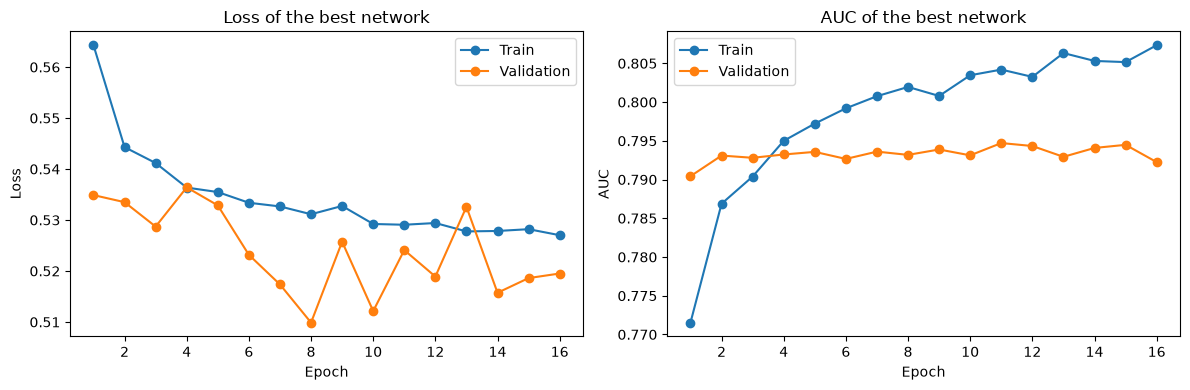

In [46]:
# Loss and AUC of the best network, epoch by epoch, on train and validation
best_network_epochs = list(range(1, len(best_network_history["loss"]) + 1))

figure, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(best_network_epochs, best_network_history["loss"], marker="o", label="Train")
axes[0].plot(best_network_epochs, best_network_history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss of the best network")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(best_network_epochs, best_network_history["auc"], marker="o", label="Train")
axes[1].plot(best_network_epochs, best_network_history["val_auc"], marker="o", label="Validation")
axes[1].set_title("AUC of the best network")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].legend()

plt.tight_layout()
plt.show()

**How to read the chart:** while both lines improve together, the network is learning patterns that work on new data. When the training line keeps improving and the validation line stops following, the network starts to memorise. That is where early stopping ends training.

Two notes:

- the training and validation losses cannot be compared directly, because in training the errors are weighted by the class weights and in validation they are not;
- the AUC in the chart is the one Keras computes during training, as an approximation. The one in the table is computed by scikit-learn from the final probabilities and is the one that counts.

In [47]:
# AUC of the best network on train and validation, computed the same way as for the random forest
network_proba_train = best_network.predict(X_train_nn, verbose=0).ravel()
network_proba_val = best_network.predict(X_val_nn, verbose=0).ravel()

network_auc_train = roc_auc_score(y_train_nn, network_proba_train)
network_auc_val = roc_auc_score(y_val_nn, network_proba_val)

print(f"Neural network, train AUC: {network_auc_train:.4f}")
print(f"Neural network, validation set AUC: {network_auc_val:.4f}")

Neural network, train AUC: 0.8178
Neural network, validation set AUC: 0.7947


#### 6.4 The two models side by side

A table with the AUC of the two tuned models, on train and on the validation set. The full comparison, with the test set and the other metrics, is in Step 7.

In [48]:
# AUC of each model on train and validation
model_table = pd.DataFrame({
    "model": ["Random forest", "Neural network"],
    "train_auc": [round(forest_auc_train, 4), round(network_auc_train, 4)],
    "val_auc": [round(forest_auc_val, 4), round(network_auc_val, 4)],
})
model_table["train_val_gap"] = (model_table["train_auc"] - model_table["val_auc"]).round(4)

print("AUC of the two tuned models:\n")
print(model_table)

AUC of the two tuned models:

            model  train_auc  val_auc  train_val_gap
0   Random forest     0.8837   0.8047         0.0790
1  Neural network     0.8178   0.7947         0.0231


**A note on validation.** Two forms of validation are used here: the random forest is tuned with K-fold cross-validation inside the training set, and the network is tuned with the separate validation set. That validation set is also used to compare the two models on data neither of them used to learn its weights.

# Step 7. Evaluation and interpretation

Now the **test set**, kept aside until here, is used. Neither model has seen it, in training or in tuning, so the results below are the best estimate of how the models would perform on new clients.

#### 7.1 Predictions on the test set

Each model returns, for each contact, the **probability of subscription**. To turn the probability into a prediction, a **threshold of 0.5** is used: if the probability is 0.5 or higher, the model predicts "subscribes" (1); if lower, it predicts "does not subscribe" (0).

In [49]:
# Decision threshold: from this probability up, the model predicts a subscription
decision_threshold = 0.5

# Probability of subscription predicted by each model for the test contacts
forest_proba_test = best_forest.predict_proba(X_test)[:, 1]
network_proba_test = best_network.predict(X_test_nn, verbose=0).ravel()

# Predictions (0 or 1): compare the probability with the threshold
forest_pred_test = (forest_proba_test >= decision_threshold).astype(int)
network_pred_test = (network_proba_test >= decision_threshold).astype(int)

print(f"Test contacts: {len(y_test)}, of which {y_test.sum()} with a subscription")
print(f"Subscriptions predicted by the random forest: {forest_pred_test.sum()}")
print(f"Subscriptions predicted by the neural network: {network_pred_test.sum()}")

Test contacts: 6177, of which 696 with a subscription
Subscriptions predicted by the random forest: 1095
Subscriptions predicted by the neural network: 1194


#### 7.2 Metrics

Five metrics are computed for each model:

- **accuracy:** of all predictions, how many are correct;
- **precision:** of the contacts the model says will subscribe, how many actually do;
- **recall:** of the real subscriptions, how many the model found;
- **F1-score:** the harmonic mean of precision and recall;
- **AUC:** the area under the ROC curve, which measures whether the model ranks clients well.

Precision, recall and F1-score refer to the "subscribed" class, which is the one we want to find. For comparison, a model that **always answers "does not subscribe"** is added.

In [50]:
# Metrics of each model on the test set
metrics_table = pd.DataFrame({
    "model": ["Random forest", "Neural network"],
    "accuracy": [accuracy_score(y_test, forest_pred_test), accuracy_score(y_test, network_pred_test)],
    "precision": [precision_score(y_test, forest_pred_test), precision_score(y_test, network_pred_test)],
    "recall": [recall_score(y_test, forest_pred_test), recall_score(y_test, network_pred_test)],
    "f1": [f1_score(y_test, forest_pred_test), f1_score(y_test, network_pred_test)],
    "auc": [roc_auc_score(y_test, forest_proba_test), roc_auc_score(y_test, network_proba_test)],
})

print("Metrics on the test set (threshold 0.5):\n")
print(metrics_table.round(4))

# Baseline: always answer "does not subscribe"
always_no_accuracy = (y_test == 0).mean()
print(f"\nAccuracy of a model that always answers \"does not subscribe\": {always_no_accuracy:.4f} (recall 0: finds no subscriptions)")

Metrics on the test set (threshold 0.5):

            model  accuracy  precision  recall      f1     auc
0   Random forest    0.8551     0.4091  0.6437  0.5003  0.8094
1  Neural network    0.8388     0.3744  0.6422  0.4730  0.7988

Accuracy of a model that always answers "does not subscribe": 0.8873 (recall 0: finds no subscriptions)


In [51]:
# Classification report of each model (precision, recall and F1-score of each class)
print("Random forest, classification report on the test set:\n")
print(classification_report(y_test, forest_pred_test, target_names=["did not subscribe", "subscribed"]))

print("Neural network, classification report on the test set:\n")
print(classification_report(y_test, network_pred_test, target_names=["did not subscribe", "subscribed"]))

Random forest, classification report on the test set:

                   precision    recall  f1-score   support

did not subscribe       0.95      0.88      0.92      5481
       subscribed       0.41      0.64      0.50       696

         accuracy                           0.86      6177
        macro avg       0.68      0.76      0.71      6177
     weighted avg       0.89      0.86      0.87      6177

Neural network, classification report on the test set:

                   precision    recall  f1-score   support

did not subscribe       0.95      0.86      0.90      5481
       subscribed       0.37      0.64      0.47       696

         accuracy                           0.84      6177
        macro avg       0.66      0.75      0.69      6177
     weighted avg       0.89      0.84      0.86      6177



**How to read these metrics:** both models have lower accuracy than the model that always answers "does not subscribe". That model scores high because almost nobody subscribes, but it does not find a single interested client. The two trained models trade some accuracy for recall: they find a good share of the subscriptions, at the cost of false alarms.

This is the effect of the class weights.

#### 7.3 Confusion matrices

The confusion matrix compares the real answers (rows) with the predictions (columns). In scikit-learn's layout:

- top left, the **true negatives** (did not subscribe, and the model got it right);
- top right, the **false positives** (the model predicted a subscription, but there was none);
- bottom left, the **false negatives** (there was a subscription, but the model did not predict it);
- bottom right, the **true positives** (subscribed, and the model got it right).

Random forest confusion matrix:
[[4834  647]
 [ 248  448]]

Neural network confusion matrix:
[[4734  747]
 [ 249  447]]


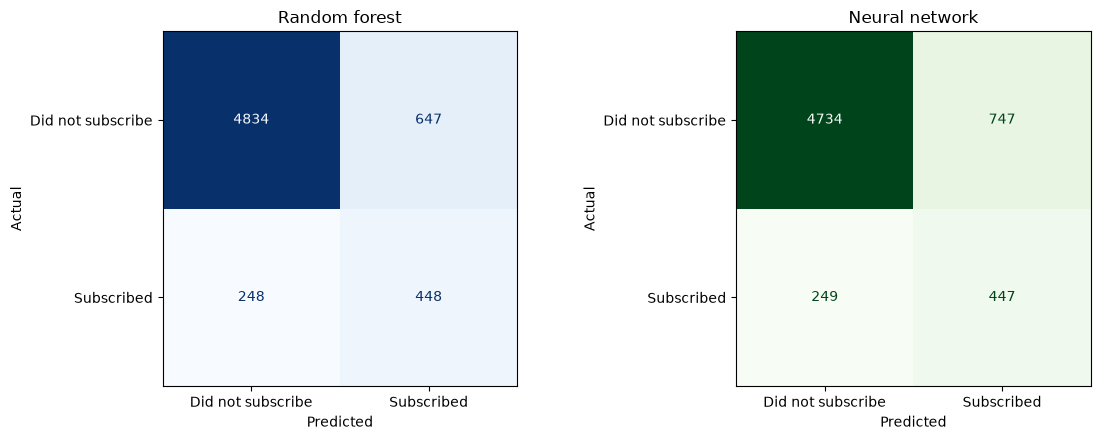

In [52]:
# Confusion matrices of the two models, side by side
forest_confusion_matrix = confusion_matrix(y_test, forest_pred_test)
network_confusion_matrix = confusion_matrix(y_test, network_pred_test)

print("Random forest confusion matrix:")
print(forest_confusion_matrix)
print("\nNeural network confusion matrix:")
print(network_confusion_matrix)

figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))

forest_display = ConfusionMatrixDisplay(confusion_matrix=forest_confusion_matrix, display_labels=["Did not subscribe", "Subscribed"])
forest_display.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Random forest")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

network_display = ConfusionMatrixDisplay(confusion_matrix=network_confusion_matrix, display_labels=["Did not subscribe", "Subscribed"])
network_display.plot(ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title("Neural network")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

#### 7.4 ROC curves

The ROC curve shows a model's performance at **every threshold**, not just 0.5. The vertical axis is the true positive rate (recall) and the horizontal axis the false positive rate. The closer the curve gets to the top-left corner, the better. The dashed diagonal is what a model answering at random would do (AUC of 0.5).

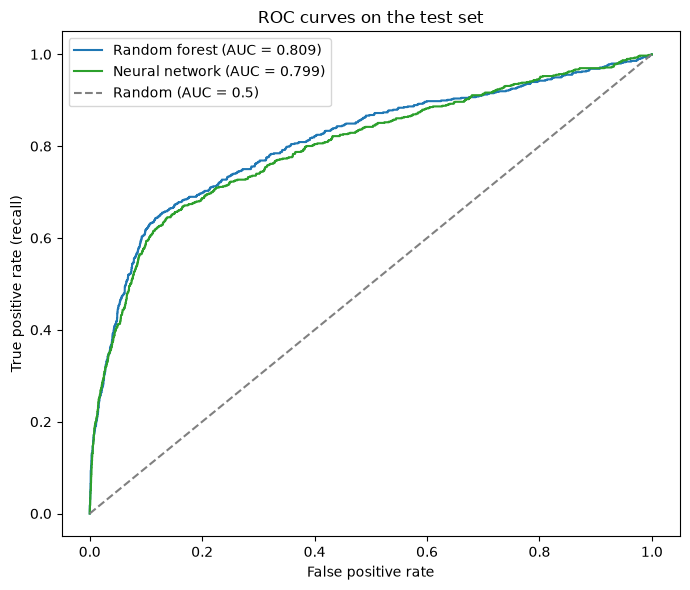

In [53]:
# ROC curve points for each model: false positive rate and true positive rate at each threshold
forest_fpr, forest_tpr, forest_thresholds = roc_curve(y_test, forest_proba_test)
network_fpr, network_tpr, network_thresholds = roc_curve(y_test, network_proba_test)

forest_auc_test = roc_auc_score(y_test, forest_proba_test)
network_auc_test = roc_auc_score(y_test, network_proba_test)

plt.figure(figsize=(7, 6))
plt.plot(forest_fpr, forest_tpr, color="tab:blue", label=f"Random forest (AUC = {forest_auc_test:.3f})")
plt.plot(network_fpr, network_tpr, color="tab:green", label=f"Neural network (AUC = {network_auc_test:.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random (AUC = 0.5)")
plt.title("ROC curves on the test set")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend()
plt.tight_layout()
plt.show()

#### 7.5 Feature importance

The random forest stores, in `feature_importances_`, the **importance of each feature**: how much each one helped the trees separate subscriptions from non-subscriptions. The importances add up to 1. The chart shows the top 15.

The neural network has no direct equivalent, so this chart is for the random forest only.

The 15 most important features for the random forest:

                 feature  importance
0   economic_component_1      0.2284
1   economic_component_3      0.1348
2   economic_component_2      0.1250
3       contacted_before      0.0644
4       poutcome_success      0.0457
5                    age      0.0389
6       contact_cellular      0.0341
7      contact_telephone      0.0336
8              month_may      0.0230
9   poutcome_nonexistent      0.0226
10              previous      0.0218
11              campaign      0.0195
12             month_oct      0.0128
13            default_no      0.0126
14       default_unknown      0.0123

Together, these 15 account for 83.0% of the total importance.


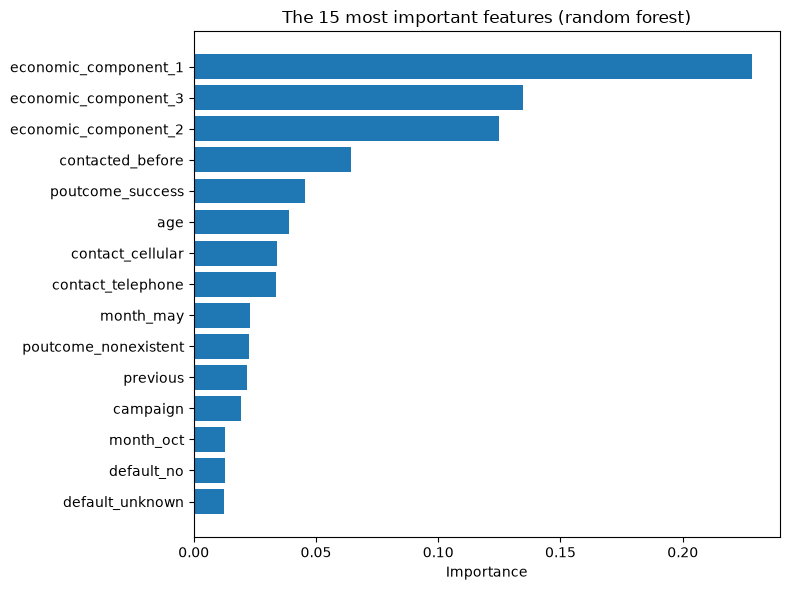

In [54]:
# Importance of each feature according to the random forest, from highest to lowest
importances = pd.DataFrame({
    "feature": X_train.columns,
    "importance": best_forest.feature_importances_,
})
importances = importances.sort_values(by="importance", ascending=False).reset_index(drop=True)

# The top 15
top_importances = importances.head(15)
print("The 15 most important features for the random forest:\n")
print(top_importances.round(4))
print(f"\nTogether, these 15 account for {top_importances['importance'].sum() * 100:.1f}% of the total importance.")

# Horizontal bar chart (reversed, so the most important is on top)
plt.figure(figsize=(8, 6))
plt.barh(top_importances["feature"][::-1], top_importances["importance"][::-1], color="tab:blue")
plt.title("The 15 most important features (random forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

#### 7.6 Model comparison

The table brings together each model's AUC on train, validation and test. If the test AUC is close to the validation AUC, the models generalise well: they behave on new data as expected.

In [55]:
# AUC of each model on train, validation and test
comparison_table = pd.DataFrame({
    "model": ["Random forest", "Neural network"],
    "train_auc": [forest_auc_train, network_auc_train],
    "val_auc": [forest_auc_val, network_auc_val],
    "test_auc": [forest_auc_test, network_auc_test],
})

print("AUC of each model on train, validation and test:\n")
print(comparison_table.round(4))

AUC of each model on train, validation and test:

            model  train_auc  val_auc  test_auc
0   Random forest     0.8837   0.8047    0.8094
1  Neural network     0.8178   0.7947    0.7988


#### 7.7 Choosing the final model

The chosen model is the **random forest**, for three reasons:

1. **It has better test results on every metric.** The AUC is 0.8094 against 0.7988 for the neural network, and the F1-score is 0.5003 against 0.4730. The advantage is small, but it shows up on both the validation set and the test set.
2. **It finds the same subscriptions with fewer wasted calls.** Both models find practically the same number of subscriptions (448 and 447, out of 696), but the random forest does it with 647 false alarms and the network with 747. That is 100 fewer calls for the same result.
3. **It shows how it decides.** The random forest shows which variables weigh most, which was one of the project's goals. The neural network works as a black box.

The random forest's weak point is that it **memorises the training data more** (overfitting): its AUC drops from 0.8837 on train to 0.8094 on test, while the network's only drops from 0.8178 to 0.7988. Even so, the test AUC (0.8094) is very close to the validation AUC (0.8047), which shows the model behaves on new data as expected.

**What the model gives the bank.** On the test set, the random forest flagged 1,095 of 6,177 contacts, that is, 17.7%. Those contacts held 448 of the 696 subscriptions (64%). Calling only those clients, 41 in every 100 calls end in a subscription. Calling everyone, it is 11 in every 100.

**What the variables show.** The three most important features are the economic components, which together account for about 49% of the importance: the economic moment of the call weighs more than the client's characteristics. Next come the contact history (`contacted_before` and `poutcome_success`), age and contact type. Of the variables created in this project, `contacted_before` is 4th and the economic components take the top three places. `age_group` is not in the top 15: age weighs mainly through the `age` column, in 6th place.

# Step 8. Conclusions

#### Summary of the results

The goal was to predict, before calling, whether a client will subscribe to a term deposit. The starting point was 41,188 contacts from a Portuguese bank, of which only 11.27% ended in a subscription.

- The data was cleaned and prepared: 12 duplicate rows were removed, the missing values were handled, the call duration was removed and the variables `contacted_before` and `age_group` were created. The five economic indicators were reduced to three components with PCA.
- Two models were trained, a random forest and a neural network, tuned with grid search and random search.
- The final model, the random forest, has a test AUC of 0.8094. It finds 64% of the subscriptions and is right about 41% of the clients it flags, almost four times better than calling at random.
- What weighs most in the prediction is the economic context and the client's contact history.

#### Challenges

- **Class imbalance.** With almost 89% "no" answers, accuracy is misleading: always answering "no" gives 0.8873 and finds no one. Class weights were used in training, and the models were evaluated with AUC, precision, recall and F1-score.
- **The `duration` column.** It is strongly linked to the outcome, as seen in section 2.6, but only exists after the call. It was removed so the model uses only what the bank knows before calling. No model was trained with it, so it is not known how much the metrics would improve.
- **Not leaking test information into the model.** Standardisation and PCA learn from the data, so they were fitted on the training set only, after the split. That meant explaining these steps earlier and computing them later.
- **Hidden missing values.** There were no null values: they were marked as "unknown" and as 999. In `default`, "unknown" carried information and was kept.
- **The neural network gained little from tuning.** The eight configurations tested all scored between 0.7911 and 0.7947 validation AUC. On this data, the network architecture matters little.

#### Limitations

- The data is from 2008 to 2010, a period of economic crisis. A model trained on it may not work today without retraining on recent data.
- The data was split at random. In reality, the model would be trained on the past to predict the future. Whether it performs as well in that scenario was not tested.
- Precision is 41%: of every 100 clients flagged, 59 do not subscribe. The model is for ranking clients and deciding whom to call first, not for knowing for sure who will subscribe.
- PCA removed the direct reading of the economic indicators. We know the economy matters, but not which of the five indicators matters most.

#### Ideas for future work

The ideas below were not tested in this project:

- **Split the data by date**, training on older contacts and testing on more recent ones, to simulate real use.
- **Choose the decision threshold** based on the cost of each call and the value of each subscription, instead of using 0.5.
- **Try other models**, such as gradient boosting, which usually does well on tabular data.
- **Use an explainability technique** such as SHAP, to see in which direction each variable pushes the prediction and to explain the neural network.
- **Compare the model with and without PCA**, to measure what is gained and what is lost in interpretability.
- **Check the model's fairness**, for example whether it treats clients differently depending on their age.